# Sistema multiagente ReAct para auditoría de hechos, razonamiento matemático y código

Proyecto final de Procesamiento de Lenguaje Natural, UTEC 2026.

Integrantes: Ricardo Amiel Acuña Villogas, Juan Leibniz Aquino Espinoza y Josué Nehemías Velo Poma.

Tres agentes coordinados por un grafo de estados de LangGraph resuelven consultas de WikiQA, GSM8K y MBPP. El **Investigador** razona con el ciclo Thought, Action, Observation y usa una base vectorial FAISS, búsqueda web y un ejecutor de Python. El **Auditor de Hechos** rechaza el reporte si detecta datos sin respaldo o código que no pasa los tests, y devuelve el flujo al Investigador. El **Redactor** escribe la respuesta final citando las fuentes. El orquestador es Qwen2.5 7B Instruct cuantizado en 4 bits NF4.

Contenido:

1. Entorno y hardware.
2. Base de conocimiento e índice vectorial.
3. Grafo de agentes.
4. Ejecución completa del flujo.
5. Estimación de tiempos.
6. Evaluación sobre 50 consultas: tabla comparativa frente a Naive RAG.
7. Ablaciones: Auditor, tamaño del modelo, latencia por agente y recuperación.
8. Conclusiones.

## 1. Entorno y hardware

La primera celda detecta si el notebook corre en Google Colab, en el clúster Khipu o en una máquina local. En Colab instala las dependencias y clona el repositorio del proyecto; en los otros entornos usa la carpeta del proyecto. Luego elige el orquestador según la memoria de la GPU: con 8 GB o más usa el modelo de 7B, y con menos (por ejemplo una MX450 de 2 GB) usa el de 1.5B.

In [1]:
import os, sys, socket, subprocess
from pathlib import Path

EN_COLAB = "COLAB_RELEASE_TAG" in os.environ
EN_KHIPU = "SLURM_JOB_ID" in os.environ or "khipu" in socket.gethostname()
REPO = "https://github.com/ricardoamiel/auditor-react.git"  # repositorio público del proyecto

if EN_COLAB:
    if not Path("/content/proyecto").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/proyecto"], check=True)
    os.chdir("/content/proyecto")
    %pip install -q langgraph faiss-cpu sentence-transformers bitsandbytes ddgs
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path("codes").resolve()))
print("Entorno:", "Google Colab" if EN_COLAB else "Khipu" if EN_KHIPU else "Local", "| carpeta:", Path.cwd())

Entorno: Khipu | carpeta: ~/nlp_final


In [2]:
import torch
from config import LLM_7B, LLM_15B, INDEX_DIR, DATA, RESULTS, TOP_K

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    VRAM = props.total_memory / 1e9
    print(f"GPU: {props.name} con {VRAM:.1f} GB")
else:
    VRAM = 0
    print("Sin GPU: el flujo correrá en CPU con el modelo pequeño (lento)")
MODELO = LLM_7B if VRAM >= 8 else LLM_15B
print("Orquestador elegido:", MODELO)

GPU: NVIDIA RTX A6000 con 50.9 GB
Orquestador elegido: Qwen/Qwen2.5-7B-Instruct


## 2. Base de conocimiento e índice vectorial

El corpus une tres fuentes: un documento por cada título de Wikipedia de WikiQA (todas sus oraciones), los problemas resueltos de GSM8K train y los programas de MBPP train. Cada documento se codifica con all MiniLM L6 v2, elegido en la ablación de la sección 7 frente al modelo multilingüe del laboratorio de RAG y a bge small, y se indexa en FAISS con producto interno sobre vectores normalizados, que equivale a la similitud coseno. Las consultas de evaluación de GSM8K y MBPP salen de los splits de test, por lo que nunca están dentro del índice.

In [3]:
import json
import pandas as pd

if not (INDEX_DIR / "embedder.txt").exists():  # en Colab se construye una vez (un par de minutos)
    subprocess.run([sys.executable, "codes/prepare_data.py", "--solo-indice"], check=True)

import tools
from retriever import Retriever
tools.RETRIEVER = Retriever.cargar(device="cuda" if torch.cuda.is_available() else "cpu")
consultas = json.load(open(DATA / "consultas_eval.json"))

docs = pd.DataFrame(tools.RETRIEVER.docs)
resumen = pd.DataFrame({"documentos en el índice": docs.fuente.value_counts(),
                        "consultas de evaluación": pd.Series([q["tipo"] for q in consultas]).value_counts()
                        .rename({"wiki": "wikiqa", "math": "gsm8k", "code": "mbpp"})})
resumen

,documentos en el índice,consultas de evaluación
gsm8k,7473,15
mbpp,474,15
wikiqa,2811,20


In [4]:
texto, encontrados = tools.buscar_kb("how are glacier caves formed?")
print(texto[:900])

[wiki_0] Glacier cave. A partly submerged glacier cave on Perito Moreno Glacier . The ice facade is approximately 60 m high Ice formations in the Titlis glacier cave A glacier cave is a cave formed within the ice of a glacier . Glacier caves are often called ice caves , but this term is properly used to describe bedrock caves that contain year-round ice.
[wiki_2079] Limestone. Limestone is a sedimentary rock composed largely of the minerals calcite and aragonite , which are different crystal forms of calcium carbonate (CaCO3). Many limestones are composed from skeletal fragments of marine organisms such as coral or foraminifera . Limestone makes up about 10% of the total volume of all sedimentary rocks. The solubility of limestone in water and weak acid solutions leads to karst landscapes, in which water erodes the limestone over thousands to millions of years. Most cave systems are thro


## 3. Grafo de agentes

El estado compartido guarda la pregunta, los pasos ReAct, las observaciones, el reporte, el veredicto y la traza. Las aristas punteadas son condicionales: el Investigador va a Herramientas mientras emita una acción y al Auditor cuando escribe su reporte; el Auditor devuelve el flujo al Investigador si rechaza o pasa al Redactor si aprueba. El Auditor combina dos guardrails: uno determinista (sin evidencia, o código que no pasa los tests) y uno con el LLM que contrasta el reporte con las observaciones.

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	Investigador(Investigador)
	Herramientas(Herramientas)
	Redactor(Redactor)
	Auditor(Auditor)
	__end__([<p>__end__</p>]):::last
	Auditor -.-> Investigador;
	Auditor -.-> Redactor;
	Herramientas --> Investigador;
	Investigador -.-> Auditor;
	Investigador -.-> Herramientas;
	__start__ --> Investigador;
	Redactor --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



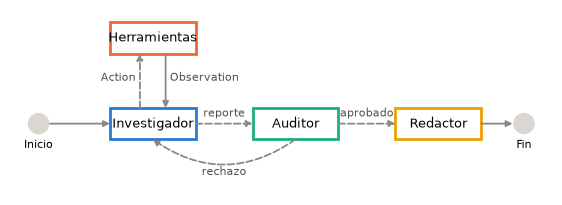

In [5]:
from llm import LLM
from agents import construir_grafo, estado_inicial
from figures import fig_grafo

llm = LLM(MODELO)
grafo = construir_grafo(llm, con_auditor=True)
print(grafo.get_graph().draw_mermaid())
fig_grafo(grafo);

**Qué aporta la figura.** Muestra que el control no es una cadena lineal sino un grafo con dos ciclos. El ciclo corto entre Investigador y Herramientas implementa ReAct: el modelo no responde de memoria, pide evidencia y razona sobre ella. El ciclo largo que vuelve desde el Auditor es el guardrail: un reporte sin respaldo no llega al usuario, regresa al Investigador con el motivo del rechazo. Estos dos ciclos son la diferencia arquitectónica frente a un Naive RAG, que recorre un único camino recuperar y generar.

## 4. Ejecución completa del flujo

Se ejecuta una consulta de cada tipo y se imprime la traza: cada pensamiento, la acción elegida, la observación recibida, el veredicto del Auditor y la respuesta del Redactor.

In [6]:
import time

def mostrar(pregunta):
    llm.reiniciar_contadores()
    t0 = time.time()
    s = grafo.invoke(estado_inicial(pregunta), {"recursion_limit": 60})
    for e in s["traza"]:
        if e["tipo"] == "thought":
            print(f"[{e['nodo']}] Thought: {e['texto'][:200]}\n    Action: {e['accion']} | Input: {e['entrada'][:150]!r}")
        elif e["tipo"] == "observation":
            print(f"[{e['nodo']}] Observation: {e['texto'][:250]!r}")
        else:
            print(f"[{e['nodo']}] {e['tipo'].upper()}: {e['texto'][:400]}")
    seg = time.time() - t0
    print(f"\nTiempo: {seg:.1f} s | llamadas al LLM: {llm.llamadas} | tokens generados: {llm.tokens_out} | rechazos: {s['rechazos']}")
    return seg, llm.tokens_out

ejemplos = {t: next(q for q in consultas if q["tipo"] == t) for t in ("wiki", "math", "code")}
medidas = {}

In [7]:
print(ejemplos["wiki"]["pregunta"], "\n")
medidas["wiki"] = mostrar(ejemplos["wiki"]["pregunta"])

when the body is systemic 

[Investigador] Thought: I need to understand what "when the body is systemic" means in medical terms. Let's start by searching the knowledge base for relevant information.
    Action: buscar_kb | Input: 'when the body is systemic'
[Herramientas] Observation: '[wiki_2623] Systemic. Systemic refers to something that is spread throughout, system-wide, affecting a group or system such as a body, economy, market or society as a whole. Systemic may also refer to:\n[wiki_2295] Chronic kidney disease. Chronic kidn'
[Investigador] Thought: The term "when the body is systemic" seems to be used in the context of chronic conditions affecting the entire body. However, the exact usage in this specific phrase isn't clear from the knowledge ba
    Action: buscar_web | Input: 'when the body is systemic medical context'
[Herramientas] Observation: '[web_0] Systemic inflammatory response syndrome: In immunology, systemic inflammatory response syndrome (SIRS) is an inflammatory

In [8]:
print(ejemplos["math"]["pregunta"], "\n")
medidas["math"] = mostrar(ejemplos["math"]["pregunta"])

Sarah went to buy books from the store and spent $300 on the books. If each book was $15 and she gave an equal number of books to her 4 kids, how many books did each child get? 

[Investigador] Thought: To solve this problem, I need to first calculate the total number of books Sarah bought, then divide that number by 4 to find out how many books each child received.
    Action: execute_python | Input: '```python\ntotal_spent = 300\nprice_per_book = 15\nnumber_of_books = total_spent / price_per_book\nnumber_of_books_per_child = number_of_books / 4\nnumber_'
[Herramientas] Observation: 'ERROR: la herramienta execute_python no existe. Usa una de: buscar_kb, buscar_web, ejecutar_python.'
[Investigador] Thought: I will use the correct tool to perform the calculation.
    Action: ejecutar_python | Input: 'total_spent = 300\nprice_per_book = 15\nnumber_of_books = total_spent / price_per_book\nnumber_of_books_per_child = number_of_books / 4\nnumber_of_books_p'
[Herramientas] Observation: '(el 

In [9]:
print(ejemplos["code"]["pregunta"], "\n")
medidas["code"] = mostrar(ejemplos["code"]["pregunta"])

Write a function to find the focus of a parabola.
Your code must pass these tests:
assert parabola_focus(5,3,2)==(-0.3, 1.6)
assert parabola_focus(9,8,4)==(-0.4444444444444444, 2.25)
assert parabola_focus(2,4,6)==(-1.0, 4.125) 

[Investigador] REPORTE: ```python
def parabola_focus(a, b, c):
    x_focus = -b / (2 * a)
    y_focus = c - b**2 / (4 * a)
    return (x_focus, y_focus)
```
[Auditor] RECHAZO: El código no pasa los tests. Salida:
Traceback (most recent call last):
  File "/tmp/tmp4qf3bn3l.py", line 6, in <module>
    assert parabola_focus(5,3,2)==(-0.3, 1.6)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError
Corrige la función y pruébala con ejecutar_python antes de reportar.
[Investigador] Thought: I need to write a function that calculates the focus of a parabola given its coefficients. The general form of a parabola is y = ax^2 + bx + c. The focus of a parabola can be calculated using the form
    Action: ejecutar_python | Input: 'def parabola_focus(a, b, c):\n    

**Qué muestran las trazas.** Las tres consultas ilustran los tres comportamientos de la arquitectura. En la pregunta de hechos el Investigador consulta primero la base local, completa con la web y el Redactor responde citando ambas fuentes. En el problema matemático el sistema se corrige solo: escribe mal el nombre de la herramienta y luego olvida imprimir el resultado, y en ambos casos la observación de error lo lleva a repetir la acción correctamente; la respuesta sale de un cálculo ejecutado y no de la memoria del modelo. En la tarea de código el Auditor detecta que la fórmula es incorrecta y devuelve el assert que falla, pero el modelo de 7B no logra corregirla y la respuesta pasa con una advertencia al agotar los rechazos. Ese último caso muestra el límite del guardrail: detecta el error, pero no puede arreglarlo si el modelo no sabe cómo; en producción una respuesta con advertencia debería marcarse o derivarse a una persona en lugar de entregarse como válida.

## 5. Estimación de tiempos

Con la velocidad medida en las tres consultas anteriores se extrapola el tiempo de la evaluación completa en este hardware: 50 consultas para cada sistema multiagente y para cada Naive RAG, que genera cerca de un sexto de los tokens. El juez se estima con la misma velocidad y unos 450 tokens por respuesta. Es una cota aproximada porque la longitud de cada traza varía con la consulta.

In [10]:
seg_multi = sum(v[0] for v in medidas.values()) / len(medidas)
tok_s = sum(v[1] for v in medidas.values()) / sum(v[0] for v in medidas.values())
estimado = pd.Series({
    "Multiagente (50 consultas)": 50 * seg_multi,
    "Multiagente sin Auditor (50)": 50 * seg_multi * 0.8,
    "Naive RAG (50)": 50 * seg_multi / 6,
    "Juez para 5 sistemas (250 respuestas)": 250 * 450 / tok_s,
}) / 3600
print(f"Velocidad medida: {tok_s:.1f} tokens por segundo; {seg_multi:.0f} s por consulta multiagente")
estimado.round(2).to_frame("horas estimadas")

Velocidad medida: 18.9 tokens por segundo; 46 s por consulta multiagente


,horas estimadas
Multiagente (50 consultas),0.64
Multiagente sin Auditor (50),0.51
Naive RAG (50),0.11
Juez para 5 sistemas (250 respuestas),1.65


## 6. Evaluación sobre 50 consultas

La evaluación completa se ejecuta con codes/run_eval.py y codes/judge.py como job de SLURM en Khipu (slurm/generate.sh). Aquí se cargan sus resultados. Si se quiere repetir una parte desde el notebook, basta con fijar N_EVAL en un número de consultas por tipo; los resultados de esa prueba se guardan en results/prueba.

Métricas:

1. **Faithfulness** (RAGAS): el juez divide la respuesta en afirmaciones atómicas y marca cuáles se deducen del contexto que el sistema recuperó; el puntaje es la fracción respaldada.
2. **Answer Relevance** (RAGAS): el juez genera 3 preguntas a partir de la respuesta y se promedia su similitud coseno con la pregunta original.
3. **Acierto**: corrección según el juez en WikiQA, número exacto en GSM8K (el extractor ignora citas entre corchetes, que en una primera versión se confundían con la respuesta) y tests aprobados en MBPP.

El juez es Phi 4 (14B), de otra familia que el orquestador, para reducir el sesgo de autopreferencia.

In [11]:
N_EVAL = 0  # consultas por tipo para repetir una prueba aquí (0 usa los resultados del job)
if N_EVAL:
    from run_eval import correr
    sub = [q for t in ("wiki", "math", "code") for q in [c for c in consultas if c["tipo"] == t][:N_EVAL]]
    correr("multi_7b" if MODELO == LLM_7B else "multi_1.5b", llm, sub, RESULTS / "prueba")

In [12]:
from figures import cargar_resultados, tabla_resumen
df = cargar_resultados()
tabla = tabla_resumen(df)
tabla.round(3)

,Faithfulness,Answer Relevance,Acierto WikiQA,Recuperación WikiQA,Exactitud GSM8K,Tests MBPP,Acierto global,Segundos por consulta,Llamadas al LLM,Tokens generados
Multiagente 7B,0.837,0.680,0.80,1.0,1.000,0.533,0.78,44.641,6.16,834.56
Naive RAG 7B,0.912,0.718,0.85,1.0,1.000,0.467,0.78,4.832,1.00,92.10
Multiagente sin Auditor 7B,0.843,0.682,0.80,1.0,0.933,0.467,0.74,38.638,4.22,479.84
Multiagente 1.5B,0.470,0.435,0.65,0.4,0.600,0.133,0.48,49.409,6.84,830.18
Naive RAG 1.5B,0.778,0.642,0.60,1.0,0.733,0.133,0.50,3.837,1.00,108.04


**Lectura de la tabla.** Con el orquestador de 7B, el multiagente y el Naive RAG empatan en acierto global sobre las preguntas originales de los datasets, y el Naive RAG es ligeramente más fiel y relevante según el juez. La razón está en el tipo de pregunta: en WikiQA el documento correcto aparece entre los primeros recuperados casi siempre y los problemas de GSM8K los resuelve el 7B sin ayuda, así que una sola recuperación basta y los pasos extra solo agregan latencia y texto que el juez debe verificar. El multiagente sí supera al Naive RAG en MBPP, la tarea donde ejecutar y verificar aporta, y su versión sin Auditor queda por debajo de ambos. Con el modelo de 1.5B la arquitectura empeora el resultado: un orquestador pequeño no sigue las instrucciones de las herramientas y su propio Auditor no filtra sus errores.

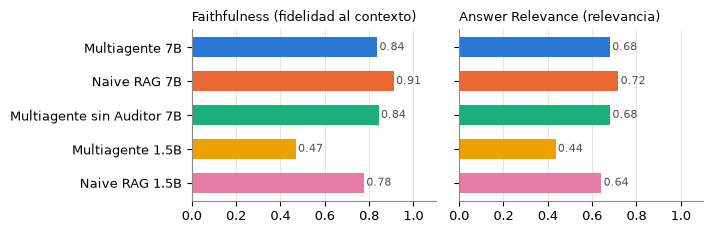

In [13]:
from figures import fig_ragas
fig_ragas(tabla);

**Qué aporta la figura.** Separa dos propiedades que el acierto no distingue. La fidelidad mide si lo afirmado está respaldado por lo recuperado y la relevancia mide si la respuesta atiende la pregunta. Con 7B ambos diseños quedan cerca, con una leve ventaja del Naive RAG porque sus respuestas son más cortas y se apoyan en un único contexto; el multiagente redacta más afirmaciones a partir de varias fuentes, incluida la web, y cada una es una oportunidad de no quedar respaldada. La caída fuerte aparece con el multiagente de 1.5B: es el sistema que más inventa, lo que confirma que el tamaño del orquestador importa más que el número de agentes.

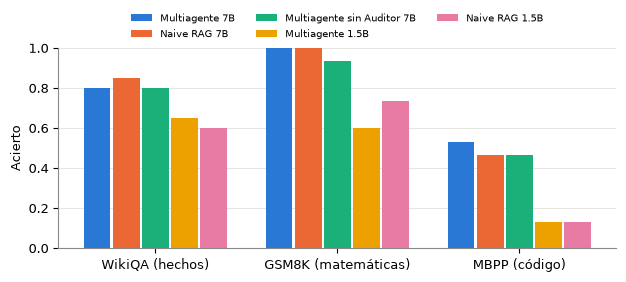

In [14]:
from figures import fig_tareas
fig_tareas(df);

**Qué aporta la figura.** Muestra que la ventaja de cada diseño depende de la tarea. En hechos simples el Naive RAG es suficiente; en matemáticas ambos llegan al techo con 7B, pero el multiagente sin Auditor pierde un problema que el guardrail sí corrige; en código el multiagente con Auditor es el único que mejora, porque ejecuta los tests y corrige. Con 1.5B ningún diseño resuelve código, lo que indica que la capacidad del modelo es el cuello de botella antes que la arquitectura.

## 7. Ablaciones

Se evalúan tres decisiones de diseño: el aporte del Auditor (multiagente con y sin él), el tamaño del orquestador (7B frente a 1.5B, que es el modelo de la aplicación web) y el costo en latencia de cada agente. Al final se compara el modelo de embeddings y el número de documentos recuperados.

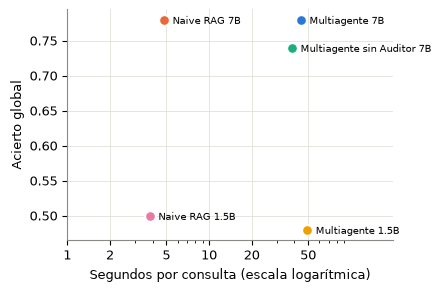

In [15]:
from figures import fig_calidad_latencia
fig_calidad_latencia(tabla);

**Qué aporta la figura.** Es la vista de producción: cada punto es un sistema según su costo y su calidad. Los Naive RAG ocupan la zona rápida y los multiagente cuestan cerca de un orden de magnitud más tiempo sin ganar acierto en estas preguntas. El multiagente de 1.5B queda en la peor posición, lento y con bajo acierto, así que reducir el modelo no es una forma válida de abaratar la arquitectura. Para un despliegue real conviene enrutar: responder con un solo paso por defecto y activar el grafo completo cuando la consulta exige varios documentos, cálculo o código.

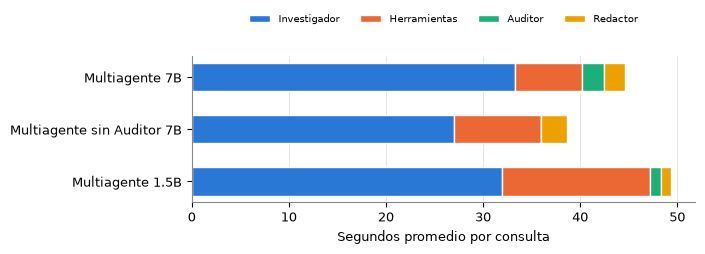

In [16]:
from figures import fig_latencia_nodos
fig_latencia_nodos(df);

**Qué aporta la figura.** Ubica dónde se gasta el tiempo dentro del grafo. Casi todo lo consume el Investigador, porque genera el razonamiento y repite el ciclo ReAct varias veces; el Auditor y el Redactor son baratos. Por eso la palanca para reducir la latencia es limitar los pasos del Investigador o enrutar las consultas simples fuera del grafo, no eliminar al Auditor, que cuesta poco y mejora el acierto.

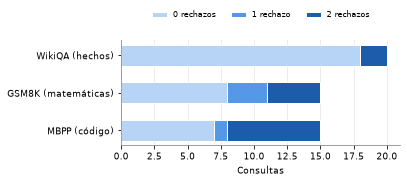

In [17]:
from figures import fig_auditor
fig_auditor(df);

**Qué aporta la figura.** Muestra en qué tareas actúa el guardrail. Los rechazos se concentran en código y matemáticas, donde la verificación es objetiva (tests y cálculos), y son raros en preguntas de hechos. Es coherente con el resultado de la tabla: el Auditor aporta donde puede comprobar algo concreto y casi no interviene donde solo puede opinar sobre el texto.

### Auditor con retroalimentación accionable

En la primera corrida el Auditor rechazaba el código sin tests ejecutados con un motivo genérico, y el Investigador repetía el mismo reporte. En la versión 2 el Auditor siempre ejecuta los tests de la tarea y devuelve el assert que falla junto con la instrucción de corregir y probar. Solo cambia el comportamiento en MBPP, así que se regeneraron únicamente esas 15 tareas; la versión 1 se conserva para esta comparación.

In [18]:
from figures import comparar_auditor_codigo
comparar_auditor_codigo().round(2)

Tests MBPP  Rechazos promedio  Segundos por consulta
Modelo Versión                                                          
7B     Sin Auditor        0.47               0.00                  35.04
       Auditor v1         0.47               1.93                  82.07
       Auditor v2         0.53               1.00                  52.85
1.5B   Auditor v1         0.13               1.60                  74.56
       Auditor v2         0.13               1.53                  72.13

**Lectura de la tabla.** Un guardrail que solo rechaza no basta: en la versión 1 el Auditor rechazaba casi siempre en código, pero el Investigador repetía el mismo reporte porque no sabía qué corregir, y el resultado no mejoraba respecto a no tener Auditor, con el doble de tiempo. Al devolver el assert que falla, la versión 2 convierte el rechazo en una instrucción útil: se necesitan menos rechazos, baja la latencia y sube la proporción de tests aprobados. Con 1.5B el cambio no ayuda, porque el modelo no logra corregir aun sabiendo el error.

In [19]:
from figures import fig_recuperacion
pd.DataFrame(json.load(open(RESULTS / "ablacion_recuperacion.json"))).set_index("embedder").round(3)

,dim,seg_indexar,ms_por_consulta,hit@1,hit@3,hit@5,hit@10
embedder,,,,,,,
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384,154.244,17.275,0.819,0.893,0.930,0.955
sentence-transformers/all-MiniLM-L6-v2,384,130.265,10.897,0.963,0.996,0.996,0.996
BAAI/bge-small-en-v1.5,384,261.892,22.526,0.975,0.992,0.996,0.996


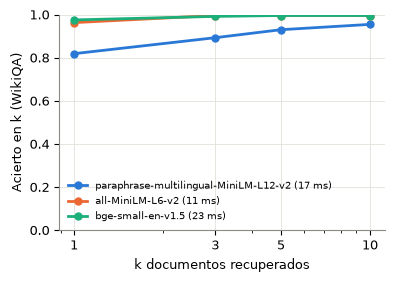

In [20]:
fig_recuperacion();

**Qué aporta la figura.** Justifica la elección del modelo de embeddings. El modelo multilingüe del laboratorio queda claramente por debajo cuando corpus y preguntas están en inglés, mientras que los dos modelos entrenados en inglés recuperan el documento correcto casi siempre desde el primer puesto. Entre ellos se eligió all MiniLM L6 porque iguala la calidad con la mitad de la latencia, y para no perder las consultas en español el Investigador escribe sus búsquedas en inglés.

### Consultas multisalto

Las preguntas de los datasets se resuelven con una sola recuperación (el documento correcto aparece entre los 3 primeros el 99 % de las veces), así que no exigen coordinar pasos. Para medir el caso que motiva la arquitectura se construyeron 15 consultas multisalto en codes/multihop.py: cada una pregunta cuántos años pasaron entre dos eventos descritos en dos documentos distintos de WikiQA (por ejemplo, la fundación de Galveston County y la de Atlanta), con el año verificado en el texto. Ambos sistemas reciben la misma instrucción de terminar con la línea Final answer.

,Acierto,Ambos documentos recuperados,Segundos por consulta,Llamadas al LLM
Multiagente 7B,0.93,0.80,26.28,8.73
Naive RAG 7B,0.53,0.27,2.42,1.00
Multiagente sin Auditor 7B,0.93,0.80,19.88,5.73


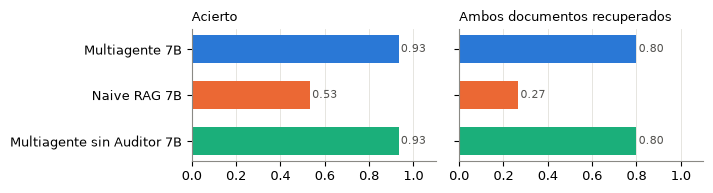

In [21]:
from figures import tabla_multisalto, fig_multisalto
multi_t = tabla_multisalto()
display(multi_t.round(2))
fig_multisalto(multi_t);

**Qué aporta la figura.** Es el resultado que justifica la arquitectura. Cuando la respuesta exige combinar dos documentos, una sola recuperación con la pregunta completa rara vez trae ambos, y todos los errores del Naive RAG ocurren justo en esos casos: el modelo pide los datos que faltan o inventa un año. El multiagente descompone la pregunta, busca cada evento por separado y resta con Python, por lo que casi duplica el acierto. La versión sin Auditor logra el mismo acierto en menos tiempo: en este experimento la ganancia viene de la descomposición y las herramientas, no del guardrail. El costo sigue siendo un orden de magnitud más de latencia, pero aquí compra una mejora real de calidad.

## 8. Conclusiones

1. **El multiagente supera al Naive RAG cuando la consulta es realmente compleja.** En las consultas multisalto, que exigen dos documentos y un cálculo, casi duplica el acierto; en código también gana porque ejecuta y verifica. En las preguntas originales de WikiQA y GSM8K, que se resuelven con una sola recuperación, ambos empatan y el Naive RAG es algo más fiel.
2. **El Auditor aporta cuando puede verificar algo concreto.** Quitarlo baja el acierto en matemáticas y código; en multisalto no cambia el acierto y solo agrega latencia. Su retroalimentación debe ser accionable: devolver el error de los tests mejoró el resultado y redujo la latencia frente a un rechazo genérico.
3. **El tamaño del orquestador pesa más que el número de agentes.** Con 1.5B el multiagente es peor que su propio Naive RAG: no sigue el formato de herramientas, inventa datos y su Auditor no los filtra.
4. **Para producción conviene enrutar.** El grafo cuesta cerca de diez veces la latencia de un paso único y casi todo ese tiempo lo consume el Investigador. Un despliegue razonable responde con Naive RAG por defecto y activa el grafo completo solo cuando la consulta pide varios documentos, cálculo o código.
5. **La evaluación necesitó su propia auditoría.** El juez inicial generaba preguntas en otro idioma, truncaba la evidencia y extraía afirmaciones del contexto, y el extractor numérico confundía citas con respuestas. Cada corrección quedó registrada y los resultados descartados se conservan en results/descartado_v1.

In [22]:
# Exporta el resumen para la tarjeta de resultados de la aplicación web
fil = [{"nombre": n, "faithfulness": r["Faithfulness"], "answer_relevance": r["Answer Relevance"],
        "acierto": r["Acierto global"], "segundos": r["Segundos por consulta"]} for n, r in tabla.iterrows()]
json.dump(fil, open("app/data/resultados.json", "w"), ensure_ascii=False, indent=1)
tabla.round(3).to_csv(RESULTS / "tabla_comparativa.csv")